<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/02_deep_training/notebooks/sesion_02_6_integrador_covertype.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/02_deep_training/notebooks/sesion_02_6_integrador_covertype.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F02_deep_training%2Fnotebooks%2Fsesion_02_6_integrador_covertype.ipynb)

# SI7011 · Sesión 02 · Ejercicio integrador: una receta de entrenamiento con MLflow
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–4 cada pieza apareció sola, sobre Fashion-MNIST, y en el 5 viste cómo registrar corridas en MLflow. Aquí **las combinas** sobre datos nuevos y registras cada corrida para poder compararlas y desplegar la mejor. No hay que inventar nada: cada TODO indica en qué notebook está la pieza.

**Datos: Covertype.** A partir de variables cartográficas de una parcela de 30 m × 30 m en Colorado, se predice cuál de **7 tipos de cobertura forestal** domina. Son 581 012 filas y 54 variables (10 numéricas + 44 indicadores 0/1), con clases muy desbalanceadas.

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir y escalar sin fuga (**TODO 1**) | `data_card.json` |
| Entrenamiento | tu modelo (**TODO 2**) y tu optimizador (**TODO 3**); 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre filas crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Duración:** 60–75 min. Con los valores por defecto, las tres corridas tardan unos 3 minutos en CPU. **Entorno:** Kaggle (agrega el dataset `uciml/forest-cover-type-dataset`) o Colab.

In [1]:
%pip install -q mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

import mlflow
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.15.0 · MLflow 3.18.0 · device cpu


/Users/macbook/orca/workspaces/si7011-Martinez-Jimenez-Saldarriaga/Santiago/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos: contrato y ficha (listo)
Es el mismo patrón de la sesión 01. El **contrato** describe qué columnas y valores acepta el modelo; se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [3]:
def load_covertype():
    hits = [p for r in [Path('/kaggle/input'), Path('.')] if r.exists() for p in r.glob('**/covtype.csv')]
    if hits:
        print('Leyendo', hits[0]); return pd.read_csv(hits[0]), hits[0]
    from sklearn.datasets import fetch_covtype
    print('covtype.csv no encontrado: descargando con sklearn.datasets.fetch_covtype')
    return fetch_covtype(as_frame=True).frame, None

df, src = load_covertype()
FEATURES = list(df.columns[:54]); NUMERIC = FEATURES[:10]; C = 7
CONTRACT = {'features': FEATURES, 'numeric': NUMERIC, 'binary': FEATURES[10:], 'classes': list(range(1, C + 1))}

def validate_rows(frame, contract=CONTRACT):
    missing = [c for c in contract['features'] if c not in frame.columns]
    if missing:
        raise ValueError(f'Faltan columnas: {missing[:3]}')
    X = frame[contract['features']]
    if X.isna().any().any():
        raise ValueError('Hay valores faltantes.')
    bad = [c for c in contract['binary'] if not X[c].isin([0, 1]).all()]
    if bad:
        raise ValueError(f'Indicadores con valores distintos de 0/1: {bad[:3]}')
    return X.to_numpy(np.float32, copy=True)

X_all = validate_rows(df)
y_all = df.iloc[:, -1].to_numpy().astype(np.int64) - 1          # clases 1..7 → 0..6
data_card = {'fuente': str(src) if src else 'sklearn.fetch_covtype',
             'sha256': hashlib.sha256(src.read_bytes()).hexdigest()[:16] if src else None,
             'filas': len(df), 'clases': np.bincount(y_all, minlength=C).tolist()}
json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(data_card)

covtype.csv no encontrado: descargando con sklearn.datasets.fetch_covtype


{'fuente': 'sklearn.fetch_covtype', 'sha256': None, 'filas': 581012, 'clases': [211840, 283301, 35754, 2747, 9493, 17367, 20510]}


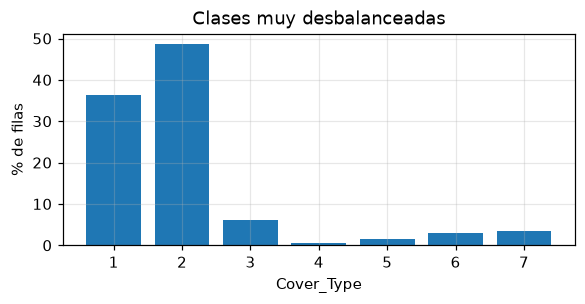

In [4]:
counts = np.bincount(y_all, minlength=C)
plt.figure(figsize=(6, 2.5)); plt.bar(range(1, C + 1), 100 * counts / counts.sum())
plt.xlabel('Cover_Type'); plt.ylabel('% de filas'); plt.title('Clases muy desbalanceadas'); plt.show()

Con este desbalance, la **accuracy** engaña: un modelo que solo prediga las dos clases grandes ya supera el 80 %. Por eso reportamos además el **F1 macro**, que promedia las 7 clases con el mismo peso.

## 2. TODO 1 · Partición y escalado sin fuga · 10 min
1. Haz una partición **estratificada** 60/20/20 (entrenamiento/validación/prueba) con `random_state=0`.
2. Toma una submuestra de `TRAIN_SIZE` filas del entrenamiento.
3. Ajusta un `StandardScaler` **solo con entrenamiento** y **solo sobre las 10 numéricas**. Los 44 indicadores 0/1 se quedan como están.

Es la misma regla de los notebooks 1–4 (`mu, sd` calculados solo con `X_train`).

In [5]:
TRAIN_SIZE = 50_000
N_NUM = len(NUMERIC)

# TODO 1 · Integrante 1
# (1) Partición estratificada 60/20/20 con random_state=0:
#     primero 60 % entrenamiento / 40 % resto; luego el resto 50/50 → 20 % validación y 20 % prueba.
X_train_full, X_rest, y_train_full, y_rest = train_test_split(
    X_all, y_all, test_size=0.40, stratify=y_all, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=0)

# (2) Submuestra estratificada de TRAIN_SIZE filas, tomada SOLO del entrenamiento
#     (validación y prueba quedan completas y nunca se tocan).
X_train, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, train_size=TRAIN_SIZE, stratify=y_train_full, random_state=0)
del X_train_full, y_train_full, X_rest, y_rest

# (3) StandardScaler ajustado SOLO con la submuestra de entrenamiento y SOLO sobre las 10 numéricas.
#     Validación y prueba se transforman con mu y sd de entrenamiento (sin fuga). Los 44 indicadores 0/1 no se tocan.
scaler = StandardScaler().fit(X_train[:, :N_NUM])
for X_part in (X_train, X_val, X_test):
    X_part[:, :N_NUM] = scaler.transform(X_part[:, :N_NUM]).astype(np.float32)

print('proporción de clases (%) · entrenamiento:', np.round(100 * np.bincount(y_train, minlength=C) / len(y_train), 2))
print('                            validación:   ', np.round(100 * np.bincount(y_val, minlength=C) / len(y_val), 2))
print('media numéricas en validación (debe ser ≈0, no exactamente 0):', np.round(X_val[:, :N_NUM].mean(0), 3))

proporción de clases (%) · entrenamiento: [36.46 48.76  6.15  0.47  1.63  2.99  3.53]
                            validación:    [36.46 48.76  6.15  0.47  1.63  2.99  3.53]
media numéricas en validación (debe ser ≈0, no exactamente 0): [-0.001  0.008 -0.001  0.003  0.004  0.006 -0.004 -0.005  0.001  0.004]


In [6]:
assert np.allclose(X_train[:, :N_NUM].mean(0), 0, atol=1e-3), 'Escala con estadísticas de entrenamiento.'
assert set(np.unique(X_train[:, N_NUM:])) <= {0.0, 1.0}, 'Los indicadores 0/1 no se escalan.'
assert len(X_train) == TRAIN_SIZE and set(y_train) == set(range(C))
T = {k: torch.as_tensor(v, device=device) for k, v in
     dict(X_train=X_train, X_val=X_val, X_test=X_test, y_train=y_train, y_val=y_val, y_test=y_test).items()}
print('entrenamiento', X_train.shape, '· validación', X_val.shape, '· prueba', X_test.shape)

entrenamiento (50000, 54) · validación (116202, 54) · prueba (116203, 54)


## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 2 con *scheduler*, clipping y norma del gradiente. `run` hace tres cosas por cada corrida:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** (notebook 3) sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: arquitectura, escalador y contrato.

MLflow guarda todo en `mlflow.db` (una base SQLite) y en `mlruns/`. Cada llamada a `run` es una **corrida** que luego se puede consultar y comparar.

In [7]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits

def train_epoch(model, opt, scheduler=None, clip=None, batch_size=512):
    model.train()
    perm = torch.randperm(len(T['y_train']), device=device)
    total, norms = 0.0, []
    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        loss = loss_fn(model(T['X_train'][b]), T['y_train'][b])  # J_𝓑(θ)
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ (notebook 2, sección 6); si hay clip: g_t ← g_t · min(1, clip/‖g_t‖)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), clip or float('inf')).item())
        opt.step()
        # η_t = s(t) · η_0 (notebook 2, sección 5)
        if scheduler is not None:
            scheduler.step()
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles (notebook 3, sección 6)
    logits = torch.cat([model(X[i:i + 8192]) for i in range(0, len(X), 8192)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y.cpu(), pred.cpu(), average='macro', zero_division=0)}, pred.cpu().numpy()

In [8]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S02-covertype'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=15, clip=None, patience=4):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(T['y_train']) / 512))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'clip': clip, 'patience': patience, 'train_size': TRAIN_SIZE,
                           'n_params': sum(p.numel() for p in model.parameters())})
        mlflow.log_metric('init_loss', evaluate(model, T['X_val'], T['y_val'])[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            train_loss, grad_norm = train_epoch(model, opt, scheduler, clip)
            va, _ = evaluate(model, T['X_val'], T['y_val'])
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[0]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1']}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping (notebook 3, sección 4): θ* = argmin_t J_val(θ_t)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({f'best_{k}': v for k, v in best.items()})
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'contract': CONTRACT,
                        'mean': scaler.mean_.astype(np.float32), 'scale': scaler.scale_.astype(np.float32)}, 'best.pt')
            mlflow.log_artifact('best.pt'); mlflow.log_artifact('data_card.json')
    return model

2026/11/23 00:06:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/23 00:06:32 INFO mlflow.store.db.utils: Updating database tables


2026/11/23 00:06:32 INFO mlflow.tracking.fluent: Experiment with name 'S02-covertype' does not exist. Creating a new experiment.


## 4. Corrida 1 · Línea base (lista)
Es un MLP de 8 capas con la inicialización por defecto, sin normalización y con SGD sin momentum: lo que uno escribiría sin haber visto esta sesión. Antes de correrlo, **predice** qué va a pasar. ¿Qué medición del notebook 1 lo anticipa?

**Predicción:**

- **Pérdida inicial ≈ ln 7 = 1.95, pero eso no significará que el modelo está sano.** Con la inicialización por defecto de PyTorch, Var(W) = 1/(3·nᵢₙ), y ReLU quita la mitad de la varianza. Entonces Var(aₗ) se multiplica por ≈ nᵢₙ·1/(3nᵢₙ)·½ = **1/6 por capa** (std × 0.41). Después de 8 capas, la señal que viene de la entrada se reduce a ≈ 0.41⁸ ≈ 8×10⁻⁴ (sin contar los sesgos), y los logits saldrán casi iguales para las 7 clases.
- **La medición del notebook 1 que lo anticipa:** std(aₗ) y ‖∇_{Wₗ}J‖ por capa. Espero que std(aₗ) caiga con la profundidad y que el gradiente de la primera capa sea órdenes de magnitud menor que el de la última.
- **Entrenamiento:** con SGD sin momentum y η = 0.05, espero una meseta cerca de **H(prior) ≈ 1.21**, que es la pérdida de un modelo que solo aprende las frecuencias de clase (36 %, 49 %, 6 %…). En esa meseta el modelo predeciría casi solo las clases 1 y 2, así que espero val_acc ≈ 0.49–0.70 y **F1 macro bajo (< 0.3)**.
- **Norma del gradiente:** pequeña (≪ 1) mientras dure la meseta. Si sale de ella, la pérdida bajará despacio y la mejor época será la última: un caso de **subajuste por optimización lenta**, no de sobreajuste. No espero early stopping.

In [9]:
def baseline_model():
    layers, n_in = [], 54
    for _ in range(8):
        layers += [nn.Linear(n_in, 256), nn.ReLU()]
        n_in = 256
    return nn.Sequential(*layers, nn.Linear(256, C))

def baseline_opt(model, total_steps):
    return torch.optim.SGD(model.parameters(), lr=0.05), None

print(f'ln 7 = {math.log(C):.3f}')
run('1-linea-base', baseline_model, baseline_opt, {'arquitectura': '8x256 plano', 'init': 'pytorch', 'optimizador': 'SGD', 'lr': 0.05});

ln 7 = 1.946


1-linea-base: mejor época 14 · val_loss 1.1963 · val_acc 0.488 · F1 macro 0.094


### Análisis de la línea base
Pérdida inicial frente a ln 7, medición de la señal y del gradiente por capa (notebook 1) y curvas leídas desde MLflow. Las figuras quedan en `docs/figuras/`.

ln 7 = 1.946 · H(prior) = 1.205
std(a_l) por capa en la init: [0.1655 0.0722 0.0389 0.0289 0.0248 0.0233 0.0221 0.0216]
‖∇W_l J‖ por capa en la init: ['3.08e-04', '1.31e-03', '1.95e-03', '3.13e-03', '6.53e-03', '1.47e-02', '3.65e-02', '8.61e-02', '2.20e-01']
logits en la init: std entre clases = 0.0412 · prob. máx. promedio = 0.150 (1/7 = 0.143)

run_id aec2093f18f740b0bf6d23dc59a893b4 · init_loss 1.9388 · best_epoch 14 · best_val_loss 1.1963 · best_val_acc 0.4876 · best_val_macro_f1 0.0937 · early_stopped = None
       train_loss  val_loss  grad_norm  val_acc  val_macro_f1
época                                                        
1          1.4656    1.2372     0.3632   0.4876        0.0937
2          1.2196    1.2125     0.0958   0.4876        0.0937
3          1.2103    1.2085     0.0777   0.4876        0.0937
4          1.2077    1.2069     0.0730   0.4876        0.0937
5          1.2064    1.2061     0.0731   0.4876        0.0937
6          1.2058    1.2055     0.0793   0.4876


% de predicciones por clase (validación): [  0. 100.   0.   0.   0.   0.   0.]
% real por clase (validación):           [36.46 48.76  6.15  0.47  1.63  2.99  3.53]
F1 por clase (validación):               [0.    0.656 0.    0.    0.    0.    0.   ]


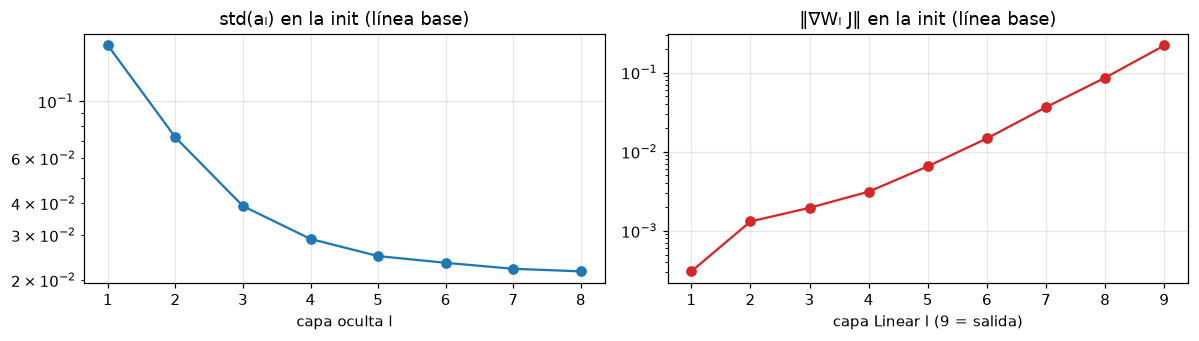

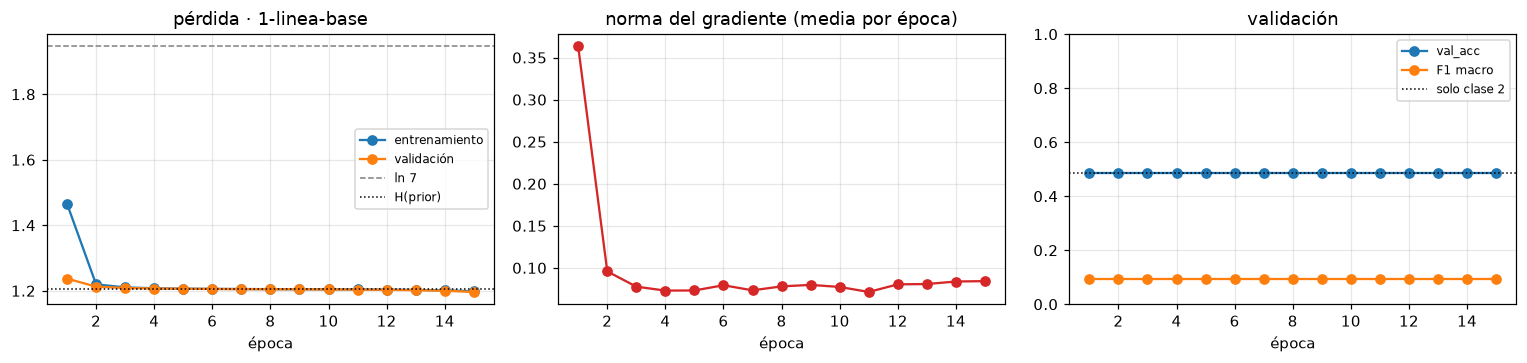

In [10]:
# Análisis de la línea base: pérdida inicial, señal y gradiente por capa, curvas
FIG = Path('docs/figuras'); FIG.mkdir(parents=True, exist_ok=True)

# (a) Referencias para la pérdida: ln 7 (predicción uniforme) y H(prior) (predecir solo las frecuencias de clase)
prior = np.bincount(y_train, minlength=C) / len(y_train)
H_prior = float(-(prior * np.log(prior)).sum())

# (b) Medición del notebook 1 en la inicialización: std(a_l) después de cada ReLU y ‖∇W_l J‖ por capa
torch.manual_seed(0)
m0 = baseline_model().to(device)
xb, yb = T['X_train'][:4096], T['y_train'][:4096]
stds, h = [], xb
with torch.no_grad():
    for layer in m0:
        h = layer(h)
        if isinstance(layer, nn.ReLU):
            stds.append(h.std().item())
logits0 = m0(xb)
loss_fn(logits0, yb).backward()
gnorms = [l.weight.grad.norm().item() for l in m0 if isinstance(l, nn.Linear)]
p0 = logits0.softmax(1).detach()
print(f'ln 7 = {math.log(C):.3f} · H(prior) = {H_prior:.3f}')
print('std(a_l) por capa en la init:', np.round(stds, 4))
print('‖∇W_l J‖ por capa en la init:', [f'{g:.2e}' for g in gnorms])
print(f'logits en la init: std entre clases = {logits0.std(1).mean().item():.4f} · '
      f'prob. máx. promedio = {p0.max(1).values.mean().item():.3f} (1/7 = {1 / C:.3f})')

# (c) Curvas de la corrida 1 desde MLflow (no desde memoria): así lo que se cita es lo registrado
client = mlflow.MlflowClient()
base = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string="tags.mlflow.runName = '1-linea-base'",
                          order_by=['attributes.start_time DESC']).iloc[0]
H = {k: [m.value for m in sorted(client.get_metric_history(base.run_id, k), key=lambda m: m.step)]
     for k in ['train_loss', 'val_loss', 'grad_norm', 'val_acc', 'val_macro_f1']}
ep = np.arange(1, len(H['train_loss']) + 1)
print(f"\nrun_id {base.run_id} · init_loss {base['metrics.init_loss']:.4f} · best_epoch {base['metrics.best_epoch']:.0f} · "
      f"best_val_loss {base['metrics.best_val_loss']:.4f} · best_val_acc {base['metrics.best_val_acc']:.4f} · "
      f"best_val_macro_f1 {base['metrics.best_val_macro_f1']:.4f} · early_stopped = {base.get('tags.early_stopped')}")
print(pd.DataFrame(H, index=pd.Index(ep, name='época')).round(4).to_string())

# (d) ¿Qué clases predice el mejor modelo de la línea base? (best.pt descargado de MLflow)
ck = torch.load(mlflow.artifacts.download_artifacts(run_id=base.run_id, artifact_path='best.pt'),
                map_location=device, weights_only=False)
mb = baseline_model().to(device); mb.load_state_dict(ck['state_dict'])
_, pred_val = evaluate(mb, T['X_val'], T['y_val'])
yv = T['y_val'].cpu().numpy()
per_class = f1_score(yv, pred_val, average=None, labels=range(C), zero_division=0)
print('\n% de predicciones por clase (validación):', np.round(100 * np.bincount(pred_val, minlength=C) / len(pred_val), 2))
print('% real por clase (validación):          ', np.round(100 * np.bincount(yv, minlength=C) / len(yv), 2))
print('F1 por clase (validación):              ', np.round(per_class, 3))

# Figura 1: medición en la inicialización
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].semilogy(range(1, 9), stds, 'o-'); axes[0].set(title='std(aₗ) en la init (línea base)', xlabel='capa oculta l')
axes[1].semilogy(range(1, 10), gnorms, 'o-', color='C3'); axes[1].set(title='‖∇Wₗ J‖ en la init (línea base)', xlabel='capa Linear l (9 = salida)')
fig.tight_layout(); fig.savefig(FIG / 'linea_base_init.png', dpi=150, bbox_inches='tight'); plt.show()

# Figura 2: curvas registradas en MLflow
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(ep, H['train_loss'], 'o-', label='entrenamiento'); axes[0].plot(ep, H['val_loss'], 'o-', label='validación')
axes[0].axhline(math.log(C), ls='--', c='gray', lw=1, label='ln 7'); axes[0].axhline(H_prior, ls=':', c='k', lw=1, label='H(prior)')
axes[0].set(title='pérdida · 1-linea-base', xlabel='época'); axes[0].legend(fontsize=8)
axes[1].plot(ep, H['grad_norm'], 'o-', c='C3'); axes[1].set(title='norma del gradiente (media por época)', xlabel='época')
axes[2].plot(ep, H['val_acc'], 'o-', label='val_acc'); axes[2].plot(ep, H['val_macro_f1'], 'o-', label='F1 macro')
axes[2].axhline(prior.max(), ls=':', c='k', lw=1, label='solo clase 2'); axes[2].set(title='validación', xlabel='época', ylim=(0, 1)); axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'linea_base_curvas.png', dpi=150, bbox_inches='tight'); plt.show()

**Diagnóstico inicial.** Todos los números salen de la corrida `1-linea-base` en MLflow y de la celda anterior.

- **Síntoma:** el modelo predice la **clase 2 en el 100 %** de las filas de validación, en todas las épocas. Por eso `val_acc` = **0.4876** no cambia en 15 épocas: es exactamente la proporción de la clase 2 (48.76 %). El F1 macro es **0.094**, que es el F1 de la clase 2 (0.656) dividido entre 7. Desde la época 2, la pérdida queda en una meseta de **1.20–1.21** (entrenamiento y validación casi iguales), justo en **H(prior) = 1.205**, que es la pérdida de un modelo que solo aprendió las frecuencias de clase. La mejor `val_loss` (1.1963) cae en la última época (`best_epoch` = 14, contando desde 0), así que nunca se activó el early stopping.
- **Pérdida inicial:** `init_loss` = **1.939 ≈ ln 7 = 1.946**. Parece sana, pero es engañosa: los logits casi no varían entre clases (std = 0.041) y la probabilidad máxima promedio es 0.150 ≈ 1/7, así que la salida **no depende de la entrada**.
- **Medición del notebook 1 en la inicialización:**
  - std(aₗ) baja de 0.166 → 0.072 → 0.039 (≈ ×0.44–0.54 por capa, cerca del √(1/6) ≈ 0.41 esperado con Var(W) = 1/(3n) y ReLU), y luego se estanca en un piso de ≈ 0.022 que ponen los sesgos. A partir de la capa 4, las capas transmiten sobre todo sesgo, no la señal de la entrada.
  - ‖∇W J‖ vale **3.1×10⁻⁴ en la primera capa** frente a **0.22 en la capa de salida**: unas 700 veces menos (el gradiente se desvanece).
- **Gradiente durante el entrenamiento:** su norma promedio cae de 0.36 en la época 1 a 0.07–0.08 desde la época 3. Con SGD sin momentum y η = 0.05, el paso efectivo es diminuto. Lo único que se aprende rápido es el sesgo de la salida (las frecuencias de clase), y por eso la pérdida baja de 1.94 a ≈ 1.21 y se queda ahí. En las últimas épocas apenas empieza a salir de la meseta (1.2041 → 1.1963 entre las épocas 10 y 15).
- **Diagnóstico:** no es sobreajuste (la brecha entre entrenamiento y validación es ≈ 0.002). Es **subajuste por un problema de optimización**: la inicialización por defecto, sin normalización, apaga la señal y el gradiente con la profundidad (notebook 1, secciones de señal e inicialización He), y SGD sin momentum con η fijo no logra salir de la meseta de «predecir la clase mayoritaria» (notebook 2).
- **¿Se cumplió la predicción?** Sí, en casi todo: pérdida inicial ≈ ln 7, meseta en H(prior), val_acc ≈ 0.49, F1 macro < 0.3, norma del gradiente ≪ 1, sin early stopping y mejor época al final. El único matiz es que la std no llegó a 8×10⁻⁴ sino a un piso de 0.022, porque la predicción ignoraba los sesgos.
- **Qué sugiere para la receta (TODO 2–3):** inicialización He y BatchNorm (std(aₗ) ≈ 1 y gradientes del mismo orden en todas las capas), y AdamW con warmup para salir rápido de la meseta. La pérdida inicial seguirá cerca de ln 7, así que la señal de que la receta funciona serán la std por capa, el gradiente y un F1 macro muy por encima de 0.094.

## 5. TODO 2 · Tu modelo · 15 min
Escribe `my_model()` y que devuelva un `nn.Sequential` (o un módulo propio) para 54 entradas y 7 salidas. Combina lo que viste:

- inicialización He (notebook 1, sección 5);
- `nn.BatchNorm1d` después de cada `Linear` oculta (notebook 3, sección 5);
- `nn.Dropout` si ves sobreajuste (notebook 3, sección 3);
- opcional: bloques residuales con LayerNorm (notebook 4, secciones 2 y 4).

Escribe la arquitectura **explícita**, sin diccionarios de configuración. Debe verse qué capas hay. Las verificaciones de la celda siguiente vienen del notebook 4, sección 5.

In [11]:
def my_model():
    # TODO 2 · Integrante 2
    # Misma forma que la línea base (8 ocultas × 256) para aislar el efecto de la init y de BatchNorm.
    # Bloque oculto: Linear → BatchNorm1d → ReLU, es decir z_l = W_l a_{l−1} + b_l, a_l = ReLU(BN(z_l)) (notebook 3, sección 5)
    # BN(z) = γ ⊙ (z − μ_𝓑) / √(s²_𝓑 + ε) + β: la escala de z_l queda en ≈ 1 en cada capa.
    # Sin Dropout: la línea base subajusta (ver la justificación después de la verificación).
    model = nn.Sequential(
        nn.Linear(54, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Linear(256, C),  # salida: 7 logits (CrossEntropyLoss aplica log_softmax por dentro)
    )
    for m in model:
        if isinstance(m, nn.Linear):
            # He: Var(W) = 2/n_in; el 2 compensa la mitad que anula ReLU (notebook 1, sección 5) · b_l = 0
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    return model

In [12]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(T['X_val'][:4096]), T['y_val'][:4096]).item()
print(m)
print(f'pérdida inicial {init_loss:.3f} (ln 7 = {math.log(C):.3f})')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la inicialización.'

xb, yb = T['X_train'][:64], T['y_train'][:64]
opt = torch.optim.Adam(m.parameters(), lr=1e-3); m.train()
for _ in range(300):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 64 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Sequential(
  (0): Linear(in_features=54, out_features=256, bias=True)
  (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=256, bias=True)
  (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): Linear(in_features=256, out_features=256, bias=True)
  (7): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): ReLU()
  (9): Linear(in_features=256, out_features=256, bias=True)
  (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Linear(in_features=256, out_features=256, bias=True)
  (13): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (14): ReLU()
  (15): Linear(in_features=256, out_features=256, bias=True)
  (16): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=T

sobreajustar 64 ejemplos: pérdida 0.0002


**Decisión sobre Dropout: no se usa.** Los números salen de la corrida `1-linea-base` (celda de análisis de la sección 4) y de la verificación anterior.

- **La línea base subajusta, no sobreajusta.** En las 15 épocas `train_loss` y `val_loss` van juntas. En la mejor época (14, contando desde 0) `train_loss` = **1.1985** y `val_loss` = **1.1963**: brecha ≈ **0.002**, con ambas en la meseta de H(prior) = 1.205. Dropout (notebook 3, sección 3) es una regularización: ayuda cuando `val_loss` se separa de `train_loss`. Aquí el problema es que el modelo no aprende, y apagar unidades solo añadiría ruido al entrenamiento.
- **Ya hay regularización en la receta:** el weight decay de AdamW (TODO 3) y el early stopping de `run`.
- **Por qué 8×256:** es la misma profundidad y el mismo ancho de la línea base. Así, en la arquitectura, la diferencia entre las corridas 1 y 2 es solo la inicialización He y BatchNorm, no la capacidad del modelo.
- **Verificación:** pérdida inicial **1.810** frente a ln 7 = 1.946, y el modelo sobreajusta 64 ejemplos hasta una pérdida de **0.0002**. El modelo y el loop están bien (notebook 4, sección 5).
- **Cuándo revisarlo:** si en la corrida 2 `val_loss` sube mientras `train_loss` sigue bajando, o el early stopping se activa pronto, Dropout es candidato para la corrida 3 (cambiar una sola cosa).

_Nota:_ la verificación se ejecutó en local con los datos de `sklearn.fetch_covtype`. La corrida `1-linea-base` reproducida así dio en MLflow exactamente las mismas curvas de `train_loss` y `val_loss` que la de la sección 4.

## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)` (notebook 2):

- `torch.optim.AdamW` con weight decay (notebook 3, sección 2);
- un `LambdaLR` con warmup lineal de **1 época** y decaimiento coseno (notebook 2, sección 5). Hay `math.ceil(TRAIN_SIZE / 512)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste para que quede registrado y fija `clip` (notebook 2, sección 6).

In [13]:
def my_opt(model, total_steps):
    # TODO 3 · Integrante 3
    # AdamW (notebook 3, sección 2): θ ← θ − η_t (m̂_t / (√v̂_t + ε) + λ θ); el weight decay λ va desacoplado del gradiente.
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-2)
    # Warmup lineal de 1 época + decaimiento coseno (notebook 2, sección 5): η_t = s(t) · η_0
    warmup_steps = math.ceil(TRAIN_SIZE / 512)  # = pasos por época con lotes de 512

    def warmup_cosine(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps  # s(t) = (t + 1) / T_w: sube de 1/T_w a 1 durante la primera época
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))  # s(t) = ½ (1 + cos(π · progreso)): baja de 1 a ≈ 0

    return opt, torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine)

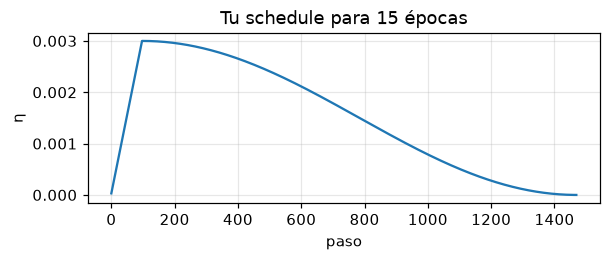

In [14]:
steps_per_epoch = math.ceil(TRAIN_SIZE / 512)
_opt, _sched = my_opt(nn.Linear(2, 2), 15 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and _opt.param_groups[0]['weight_decay'] > 0
lrs = []
for _ in range(15 * steps_per_epoch):
    lrs.append(_opt.param_groups[0]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] < 0.1 * max(lrs) and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η'); plt.title('Tu schedule para 15 épocas'); plt.show()

In [15]:
# Corrida 2 · Integrante 3: my_model (TODO 2) + my_opt (TODO 3) + clipping de la norma del gradiente en 1.0 (notebook 2, sección 6)
params = {'arquitectura': '8x256 Linear-BN-ReLU', 'init': 'He (kaiming_normal_, b=0)', 'optimizador': 'AdamW',
          'lr': 3e-3, 'weight_decay': 1e-2, 'schedule': 'warmup 1 época + coseno'}
run('2-mi-receta', my_model, my_opt, params, clip=1.0);

2-mi-receta: mejor época 14 · val_loss 0.2799 · val_acc 0.902 · F1 macro 0.838


## 7. Corrida 3 · Cambia una sola cosa · 5 min
Elige **un** cambio a tu receta y córrelo. Si escribes una función de modelo nueva, haz que su nombre termine en `_model` para que el despliegue la encuentre. Algunas opciones: quitar BatchNorm, quitar el schedule, más profundidad, más Dropout, `TRAIN_SIZE` más grande o pesos por clase en `CrossEntropyLoss`. Antes de correrlo, escribe en `params` qué esperas que pase.

_Mi cambio y mi predicción:_

- **Cambio (uno solo):** quitar `nn.BatchNorm1d` de las 8 capas ocultas con `sin_bn_model()`. Todo lo demás queda igual que en `2-mi-receta`: 8 ocultas × 256 (`Linear → ReLU`), init He (`kaiming_normal_`, sesgos en 0), `my_opt` (AdamW, η = 3·10⁻³, weight decay 10⁻², warmup de 1 época + coseno), `clip=1.0`, los mismos datos y la misma semilla. Frente a la línea base, este modelo cambia la init y el optimizador; frente a mi receta, solo le falta BatchNorm. Así mide cuánto aporta BatchNorm a la receta.
- **Predicción (escrita antes de correr):** con He (Var(W) = 2/nᵢₙ) la señal ya no se apaga con la profundidad y AdamW con warmup sale rápido de la meseta. Por eso **no** espero que se quede en H(prior) = 1.205 como la línea base: debería quedar muy por encima de ella en F1 macro. Sin BatchNorm, la escala de cada capa no se re-normaliza en cada lote. Espero una norma del gradiente más alta y más ruidosa (el `clip=1.0` se activará más seguido), una convergencia algo más lenta en las primeras épocas, y una `best_val_loss` y un F1 macro algo peores que los de `2-mi-receta`. En resumen: `1-linea-base` ≪ `3-sin-batchnorm` < `2-mi-receta`.

In [16]:
# Corrida 3 · Integrante 3 · cambia UNA cosa: sin BatchNorm. El nombre termina en _model para que BUILDERS (sección 9) lo encuentre.
def sin_bn_model():
    # Igual que my_model (8 ocultas × 256, init He, b = 0) pero sin nn.BatchNorm1d: a_l = ReLU(W_l a_{l−1} + b_l)
    model = nn.Sequential(
        nn.Linear(54, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, C),
    )
    for m in model:
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)  # He: Var(W) = 2/n_in
    return model

params = {'arquitectura': '8x256 Linear-ReLU (sin BN)', 'init': 'He (kaiming_normal_, b=0)', 'optimizador': 'AdamW',
          'lr': 3e-3, 'weight_decay': 1e-2, 'schedule': 'warmup 1 época + coseno',
          'cambio': 'quitar BatchNorm1d de las 8 capas ocultas (todo lo demás igual a 2-mi-receta)',
          'prediccion': 'supera ampliamente a la línea base (no se queda en H(prior)=1.205), pero con grad_norm más alto y ruidoso, '
                        'convergencia más lenta y best_val_loss / F1 macro algo peores que 2-mi-receta'}
run('3-sin-batchnorm', sin_bn_model, my_opt, params, clip=1.0);

3-sin-batchnorm: mejor época 9 · val_loss 0.3319 · val_acc 0.873 · F1 macro 0.784


## 8. Comparar en MLflow (listo)
`search_runs` devuelve una tabla de pandas con una fila por corrida. `get_metric_history` devuelve la curva completa de cualquier métrica.

In [17]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,
1-linea-base,1.939,14.0,1.196,0.488,0.094
2-mi-receta,1.816,14.0,0.280,0.902,0.838
3-sin-batchnorm,1.816,9.0,0.332,0.873,0.784


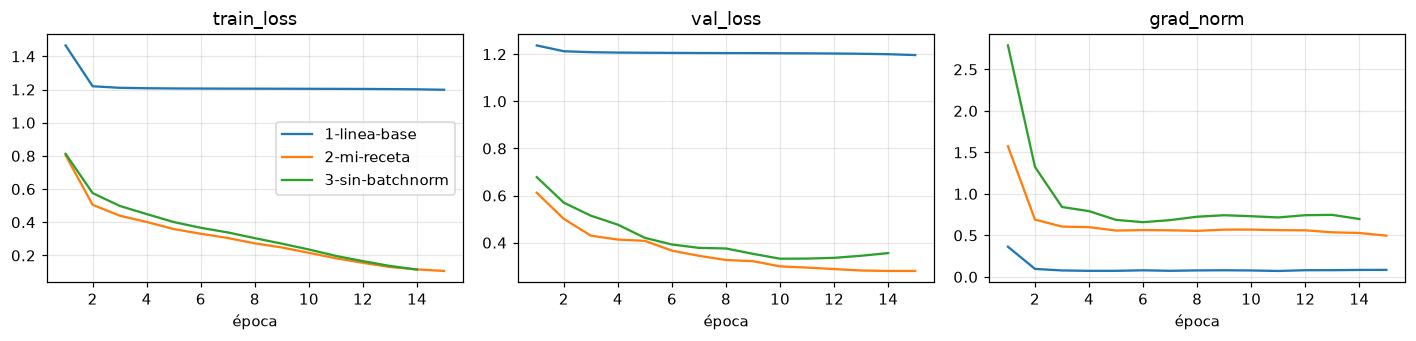

In [18]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'grad_norm']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'grad_norm']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** En local, ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000. Allí puedes seleccionar las corridas y usar *Compare*. En Kaggle o Colab, descarga `mlflow.db` y `mlruns/` y abre la interfaz en tu máquina.

## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba. Luego se carga su `best.pt` **desde MLflow**, no desde la variable en memoria, para comprobar que el artefacto está completo.

In [19]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.eval()
test_metrics, pred_test = evaluate(model, T['X_test'].cpu(), T['y_test'].cpu())
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 2-mi-receta


{'loss': 0.2835, 'acc': 0.9009, 'macro_f1': 0.842}


## 10. TODO 4 · Despliegue: predecir sobre filas crudas · 10 min
Escribe `predict_raw(ckpt, frame)`. Recibe un `DataFrame` **crudo**, con las 54 columnas en sus unidades originales (metros, grados…), y devuelve un `DataFrame` con `Cover_Type` (1–7) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_rows(frame, ckpt['contract'])`;
2. estandarizar las 10 numéricas con `ckpt['mean']` y `ckpt['scale']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()` (¿por qué? notebook 3, sección 6);
4. aplicar softmax, elegir la clase y sumar 1.

In [20]:
@torch.no_grad()
def predict_raw(ckpt, frame):
    # TODO 4 · Integrante 2 · solo se usa lo que trae ckpt (best.pt descargado de MLflow)
    # (1) contrato: columnas, sin faltantes, indicadores 0/1; si algo falla, ValueError
    X = validate_rows(frame, ckpt['contract'])
    # (2) el mismo escalado del entrenamiento, solo en las 10 numéricas: x ← (x − μ_train) / sd_train
    n_num = len(ckpt['contract']['numeric'])
    X[:, :n_num] = (X[:, :n_num] - ckpt['mean']) / ckpt['scale']
    # (3) arquitectura por nombre + pesos; eval(): BatchNorm usa los promedios móviles y Dropout se apaga,
    #     así la predicción de una fila no depende del resto del lote (notebook 3, sección 6)
    model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.eval()
    # (4) p = softmax(f_θ(x)); clase = argmax p (0..6) + 1 → Cover_Type 1..7; confianza = max p
    X = torch.as_tensor(X)
    probs = torch.cat([model(X[i:i + 8192]).softmax(1) for i in range(0, len(X), 8192)])
    conf, pred = probs.max(1)
    return pd.DataFrame({'Cover_Type': pred.numpy() + 1, 'confianza': conf.numpy()}, index=frame.index)

In [21]:
raw = X_test.copy(); raw[:, :N_NUM] = scaler.inverse_transform(raw[:, :N_NUM])     # filas crudas de prueba
raw_test = pd.DataFrame(raw, columns=FEATURES)
raw_test[CONTRACT['binary']] = raw_test[CONTRACT['binary']].round().astype(int)

out = predict_raw(ckpt, raw_test)
agree = (out['Cover_Type'].to_numpy() - 1 == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o el escalado?'

bad = raw_test.head(3).copy(); bad.loc[bad.index[0], CONTRACT['binary'][0]] = 7
try:
    predict_raw(ckpt, bad); raise AssertionError('Una fila inválida debió ser rechazada.')
except ValueError as e:
    print('2. Contrato: fila rechazada →', e)

pd.concat([raw_test.head(1000), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: fila rechazada → Indicadores con valores distintos de 0/1: ['Wilderness_Area_0']
3. predicciones.csv escrito


,Cover_Type,confianza
0,1,0.999875
1,2,0.999511
2,6,0.991928
3,2,0.838184
4,1,0.895365


## 11. Preguntas y entrega
1. La línea base, ¿hizo lo que predijiste en la sección 4? ¿Qué número del registro de MLflow lo muestra?
2. De la línea base a tu receta, ¿qué cambio crees que pesó más? ¿Cómo lo comprobarías con **una** corrida adicional?
3. ¿Se cumplió tu predicción de la corrida 3? Usa las curvas de la sección 8.
4. ¿Por qué la accuracy y el F1 macro cuentan historias distintas en estos datos?
5. ¿Qué pasaría en producción si `predict_raw` no llamara a `model.eval()`?

_Respuestas:_

Todos los números salen del experimento `S02-covertype` en MLflow (3 corridas, ejecución local en CPU con `sklearn.fetch_covtype`). `best_epoch` cuenta desde 0; las curvas de la sección 8 cuentan desde 1.

| corrida | `init_loss` | `best_epoch` | `best_val_loss` | `best_val_acc` | `best_val_macro_f1` | early stopping |
|---|---|---|---|---|---|---|
| `1-linea-base` | 1.939 | 14 | 1.196 | 0.488 | 0.094 | no |
| `2-mi-receta` | 1.816 | 14 | **0.280** | **0.902** | **0.838** | no |
| `3-sin-batchnorm` | 1.816 | 9 | 0.332 | 0.873 | 0.784 | sí (época 13) |

**1. ¿La línea base hizo lo que predije?** Sí. `init_loss` = **1.9388 ≈ ln 7 = 1.946**, pero la salida no depende de la entrada: std de los logits entre clases = 0.041 y probabilidad máxima promedio = 0.150 ≈ 1/7. La pérdida se queda en la meseta de **H(prior) = 1.205**: `val_loss` va de 1.2125 (época 2) a 1.1963 (época 15), con una brecha entre entrenamiento y validación de ≈ 0.002. El número de MLflow que mejor lo muestra es **`val_acc` = 0.4876 en las 15 épocas**, que es exactamente el 48.76 % de la clase 2. El modelo predice la clase 2 en el 100 % de las filas, y por eso `best_val_macro_f1` = **0.0937** (= 0.656/7). Además, `grad_norm` cae de 0.36 a 0.07–0.08 desde la época 3, y `best_epoch` = 14 (la última) sin `early_stopped`. Es subajuste por optimización, como se predijo.

**2. ¿Qué cambio pesó más?** La corrida 3 ya separa a BatchNorm: sin BatchNorm, pero con init He y AdamW + warmup + coseno, `best_val_loss` baja de 1.196 a **0.332**. Es decir, se logra el **94 %** de la mejora total (1.196 → 0.280); BatchNorm aporta el 6 % restante (0.332 → 0.280; F1 macro 0.784 → 0.838). Lo que pesó fue la pareja init He + optimizador. Creo que pesó más el **optimizador** (AdamW con warmup y coseno): Adam normaliza el paso de cada parámetro por √v̂ₜ, así que compensa los gradientes diminutos de las primeras capas (3·10⁻⁴ frente a 0.22 en la salida), cosa que SGD con η fijo no hace. Lo comprobaría con **una** corrida: `run('4-init-pytorch-mi-opt', baseline_model, my_opt, params, clip=1.0)`. Esa corrida difiere de `3-sin-batchnorm` solo en la init (PyTorch en vez de He). Si su `best_val_loss` queda cerca de 0.33, el optimizador explica casi todo; si se queda cerca de 1.20, la clave era la init He.

**3. ¿Se cumplió la predicción de la corrida 3?** En lo principal, sí:
- **Supera ampliamente a la línea base:** `best_val_loss` 0.332 frente a 1.196 y F1 macro 0.784 frente a 0.094. No se quedó en H(prior).
- **Gradiente más alto y más ruidoso:** en la curva `grad_norm`, la época 1 promedia **2.79** sin BatchNorm frente a **1.57** con BatchNorm (es la norma promedio antes de recortar, muy por encima de `clip = 1.0`, lo que indica recortes frecuentes en esa época), y la época 2 da 1.32 frente a 0.69. Desde la época 3, sin BatchNorm la norma queda en 0.66–0.84 y **sube** desde la época 6 (0.66 → 0.75). Con BatchNorm, después de 0.69 en la época 2 y 0.60 en la época 4, `grad_norm` se estabiliza en torno a 0.55–0.57 entre las épocas 5 y 12, y al final baja a 0.50 (época 15).
- **Convergencia más lenta:** `val_loss` en las épocas 1, 3 y 5 es 0.678 / 0.515 / 0.421 sin BatchNorm frente a 0.612 / 0.430 / 0.408 con BatchNorm.
- **Resultado final peor que `2-mi-receta`:** 0.332 frente a 0.280 en `best_val_loss`, y 0.784 frente a 0.838 en F1 macro.

Lo que **no** predije es que sin BatchNorm aparece **sobreajuste**. Desde la época 10 (`best_epoch` = 9), `train_loss` sigue bajando (0.236 → 0.115), pero `val_loss` sube (0.332 → 0.356), y el early stopping corta en la época 13 (0-index). Aun así, en esas mismas épocas `val_acc` (0.873 → 0.890) y el F1 macro (0.784 → 0.820) siguieron mejorando. El deterioro fue sobre todo de calibración: el modelo se volvió demasiado confiado en sus errores, lo que sube la pérdida aunque acierte más. `2-mi-receta`, en cambio, mejora `val_loss` hasta la última época (0.2799 en la época 15). Esto muestra que BatchNorm, además de estabilizar el gradiente, regulariza: el ruido de las estadísticas por lote actúa como regularización (notebook 3).

**4. ¿Por qué accuracy y F1 macro cuentan historias distintas?** Por el desbalance: las clases 1 y 2 suman el **85.2 %** de la prueba, y la clase 4 es solo el 0.47 % (549 filas de 116 203). La accuracy pondera cada fila por igual, así que la dominan esas dos clases; el F1 macro da el mismo peso a las 7 clases. El caso extremo es la línea base: predecir siempre la clase 2 da accuracy **0.488** con F1 macro **0.094**. En la corrida elegida (`2-mi-receta`, prueba: `acc` = **0.9009**, F1 macro = **0.842**), el F1 por clase en prueba es [0.899, 0.918, 0.881, 0.773, 0.731, 0.783, 0.909] para las clases 1–7. Las clases minoritarias 4, 5 y 6 quedan en 0.73–0.78, y eso baja el promedio macro, mientras que la accuracy (≈ F1 ponderado = 0.9007) apenas las nota. La accuracy en las filas de las clases 1–2 es 0.911, frente a 0.844 en el resto. Lo mismo pasa entre corridas: de `3-sin-batchnorm` a `2-mi-receta`, `val_acc` sube solo 0.029 (0.873 → 0.902), pero el F1 macro sube 0.054 (0.784 → 0.838), porque la mejora se concentra en clases pequeñas (F1 en validación: clase 6, 0.660 → 0.786; clase 4, 0.673 → 0.754). Este bloque de F1 por clase se calculó aparte sobre el `best.pt` de cada corrida descargado de MLflow; no aparece impreso arriba.

**5. ¿Qué pasaría si `predict_raw` no llamara a `model.eval()`?** El modelo elegido tiene 8 capas `BatchNorm1d`. En `train()`, cada capa normaliza con la media y la varianza **del lote que llega**, no con los promedios móviles del entrenamiento. Así, la predicción de una fila depende de qué otras filas vienen con ella y de cuántas son. Además, en `train()` cada pasada hacia adelante **actualiza `running_mean`/`running_var`** con las estadísticas de ese lote (aunque se use `torch.no_grad()`). Así, cada predicción va corrompiendo en silencio los promedios móviles aprendidos en el entrenamiento. Medido aparte con el `best.pt` de `2-mi-receta` en modo `train()` sobre la prueba:
- lotes de 8192 (los de `predict_raw`): acuerdo con `eval()` del **99.11 %**, es decir, la verificación `agree > 0.999` de la sección 10 fallaría;
- lotes de 512: 97.04 %;
- lotes de 64: ≈ 90 % (accuracy ≈ 0.86);
- lotes de 16: ≈ 78 % (F1 macro ≈ 0.59);
- lotes de 2: ≈ 55 % (accuracy ≈ 0.55, F1 macro ≈ 0.17);
- estas tres cifras de lotes pequeños son aproximadas: varían unas décimas de punto según el orden y la composición de cada lote;
- una sola fila, el caso típico de una API: `ValueError: Expected more than 1 value per channel when training`.

En producción, las predicciones serían inconsistentes, peores cuanto más pequeño sea el lote, y no reproducibles. Con `model.eval()`, el artefacto reproduce la evaluación de prueba al **100.00 %** (sección 10). Si hubiera Dropout, además se apagarían unidades al azar en cada predicción.


**Entrega (evento evaluativo 1, Parte B):** este notebook ejecutado, con las salidas visibles, los 4 TODO resueltos y las respuestas de arriba, en la carpeta `evento1/` del repositorio de la pareja (uno solo para todo el curso). Detalles en [`evaluations/event_1`](../../../evaluations/event_1/README.md).

**Si quieres ir más allá:** aplica a tu receta la búsqueda con Optuna del notebook 5 (`sesion_02_5_optuna_mlflow.ipynb`): cambia `train` por tu `run` y busca sobre `lr`, `weight_decay` y `dropout`. Otras ideas: exportar con `torch.export` o excluir los sesgos y los parámetros de BatchNorm del weight decay.